Saving download (6).mp4 to download (6).mp4

INPUT INFORMATION
Input video: download (6).mp4
Source resolution: 1920 x 1080
Processing resolution: 640 x 360
Frame rate: 30.0
Audio sample rate: 48000
Audio shape: (616448, 2)
Audio channels: 2

Generating repository-based audio key stream...

AUDIO RECOVERY
--------------------------------------------------
Exact sample recovery: True
Original SHA-256: ea34917097c6df39fd0b21361aa97c2689057e421160852c2f7031edbee87bcf
Decrypted SHA-256: ea34917097c6df39fd0b21361aa97c2689057e421160852c2f7031edbee87bcf
SHA-256 match: True

AUDIO ENCRYPTION DIAGNOSTICS
--------------------------------------------------
Total PCM samples: 1232896
Changed samples: 1232843
Unchanged samples: 53
Percentage changed: 99.995701
Original/encrypted correlation: 0.5768927540940944
Encrypted WAV SHA-256: 00099d46087d71074b12e0c9a4ec676b7a6eb119398f3a8e91c00a4ea63413df

Processing video frames...
Processed 10/385 frames
Processed 20/385 frames
Processed 30/385 frames
Pro

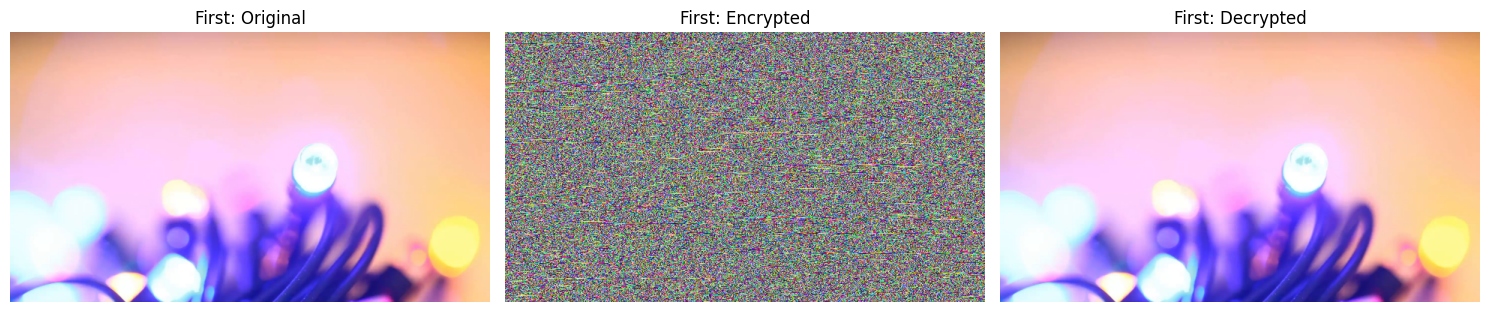

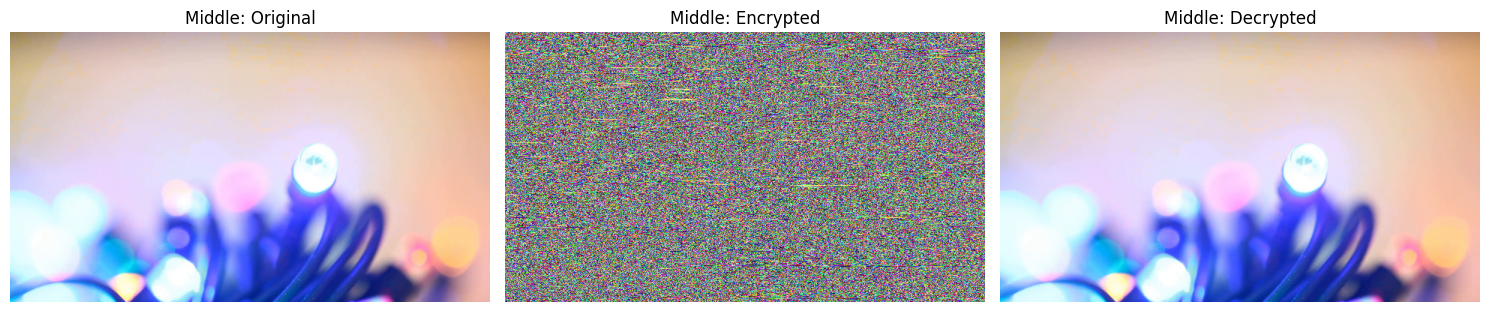

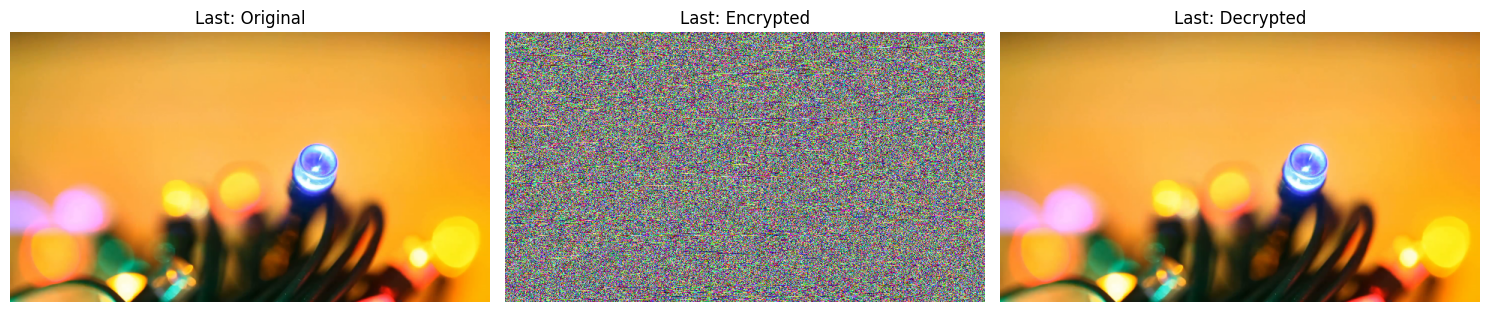


FINAL FYDP VERIFICATION
Video recovery: PASS
Audio recovery: PASS
Encrypted MKV: video + encrypted audio
Decrypted MKV: recovered video + recovered audio
Report: /content/fydp_final_video_audio/verification_report.txt



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


FYDP processing completed.


In [2]:
!pip -q install numpy scipy opencv-python-headless numba

import os
import json
import shutil
import hashlib
import subprocess
import cv2
import numpy as np
import matplotlib.pyplot as plt

from fractions import Fraction
from scipy.io import wavfile
from numba import njit
from google.colab import files
from IPython.display import Audio, display

# ================================================================
# 1. PROJECT CONFIGURATION
# ================================================================

SIGMA = 10.0
RHO = 28.0
BETA = 8.0 / 3.0
DT = 0.01

X0, Y0, Z0 = 1.0, 1.0, 1.0
WARMUP_STEPS = 1000
Q_SCALE = 256

WIDTH = 640
HEIGHT = 360
MAX_FRAMES = None

WORK = "/content/fydp_final_video_audio"

ENCRYPTED_VIDEO = "/content/encrypted_video_with_audio.mkv"
DECRYPTED_VIDEO = "/content/decrypted_video_with_audio.mkv"

# ================================================================
# 2. SYSTEM UTILITIES
# ================================================================

def run_cmd(cmd):
    result = subprocess.run(
        cmd,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(
            "Command failed:\n"
            + " ".join(map(str, cmd))
            + "\n"
            + result.stderr[-4000:]
        )
    return result.stdout


def sha256(data):
    return hashlib.sha256(data).hexdigest()


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


# ================================================================
# 3. LORENZ EQUATIONS
# ================================================================

@njit
def lorenz_step(x, y, z):
    dx = SIGMA * (y - x)
    dy = x * (RHO - z) - y
    dz = x * y - BETA * z

    x = x + dx * DT
    y = y + dy * DT
    z = z + dz * DT

    return x, y, z


# Preserve the 16-bit two's-complement bit representation.
# This is equivalent to converting a signed int16 to uint16.
@njit
def q8_8_unsigned(value):
    return int(np.rint(value * Q_SCALE)) & 0xFFFF


# ================================================================
# 4. VIDEO KEY GENERATOR
#    Matches the supplied VIDEO FRAME implementation.
# ================================================================

@njit
def generate_video_frame_key(height, width, x, y, z):
    key = np.empty((height, width, 3), dtype=np.uint8)

    for row in range(height):
        for col in range(width):

            # The supplied frame code updates BEFORE quantization.
            x, y, z = lorenz_step(x, y, z)

            x16 = q8_8_unsigned(x)
            y16 = q8_8_unsigned(y)
            z16 = q8_8_unsigned(z)

            key[row, col, 0] = (
                ((x16 >> 8) & 255) ^ (x16 & 255)
            )
            key[row, col, 1] = (
                ((y16 >> 8) & 255) ^ (y16 & 255)
            )
            key[row, col, 2] = (
                ((z16 >> 8) & 255) ^ (z16 & 255)
            )

    return key, x, y, z


# ================================================================
# 5. AUDIO KEY GENERATOR
#    Repository method:
#    1000-step warm-up
#    Q8.8 conversion
#    Key = X16 XOR Y16 XOR Z16
#
#    IMPORTANT:
#    The audio generator is independent of the video generator.
#    It resets to the repository's initial conditions.
# ================================================================

@njit
def generate_audio_key(sample_count):
    x, y, z = X0, Y0, Z0

    # Published audio implementation warm-up.
    for _ in range(WARMUP_STEPS):
        x, y, z = lorenz_step(x, y, z)

    keys = np.empty(sample_count, dtype=np.uint16)

    for i in range(sample_count):

        # Generate key from the current state, then advance.
        x16 = q8_8_unsigned(x)
        y16 = q8_8_unsigned(y)
        z16 = q8_8_unsigned(z)

        keys[i] = x16 ^ y16 ^ z16

        x, y, z = lorenz_step(x, y, z)

    return keys


# ================================================================
# 6. UPLOAD ONE VIDEO
# ================================================================

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one video file.")

input_video = os.path.abspath(next(iter(uploaded.keys())))

# ================================================================
# 7. PREPARE OUTPUT DIRECTORIES
# ================================================================

if os.path.exists(WORK):
    shutil.rmtree(WORK)

os.makedirs(WORK)

ORIGINAL_DIR = os.path.join(WORK, "original_frames")
ENCRYPTED_DIR = os.path.join(WORK, "encrypted_frames")
DECRYPTED_DIR = os.path.join(WORK, "decrypted_frames")

for folder in (ORIGINAL_DIR, ENCRYPTED_DIR, DECRYPTED_DIR):
    os.makedirs(folder)

ORIGINAL_WAV = os.path.join(WORK, "original_audio.wav")
ENCRYPTED_WAV = os.path.join(WORK, "encrypted_audio.wav")
DECRYPTED_WAV = os.path.join(WORK, "decrypted_audio.wav")

# ================================================================
# 8. INSPECT INPUT VIDEO
# ================================================================

metadata = json.loads(run_cmd([
    "ffprobe", "-v", "error",
    "-select_streams", "v:0",
    "-show_entries",
    "stream=width,height,avg_frame_rate,r_frame_rate",
    "-of", "json",
    input_video
]))

if not metadata.get("streams"):
    raise ValueError("The uploaded file has no video stream.")

stream = metadata["streams"][0]

fps_string = stream.get("avg_frame_rate", "0/0")

if fps_string in ("0/0", "N/A", None):
    fps_string = stream.get("r_frame_rate", "0/0")

fps = Fraction(fps_string)

if fps <= 0:
    raise ValueError("Could not determine the input frame rate.")

# ================================================================
# 9. EXTRACT SOURCE AUDIO AS 16-BIT PCM WAV
# ================================================================

audio_streams = json.loads(run_cmd([
    "ffprobe", "-v", "error",
    "-select_streams", "a",
    "-show_entries", "stream=index",
    "-of", "json",
    input_video
]))

if not audio_streams.get("streams"):
    raise ValueError(
        "The uploaded video has no audio stream. "
        "Please upload a video containing audio."
    )

run_cmd([
    "ffmpeg", "-y", "-v", "error",
    "-i", input_video,
    "-map", "0:a:0",
    "-vn",
    "-c:a", "pcm_s16le",
    ORIGINAL_WAV
])

sample_rate, original_audio = wavfile.read(ORIGINAL_WAV)

if original_audio.dtype != np.int16:
    raise ValueError("Audio must be signed 16-bit PCM.")

if original_audio.ndim not in (1, 2):
    raise ValueError("Only mono/stereo audio is supported.")

if original_audio.ndim == 2 and original_audio.shape[1] != 2:
    raise ValueError("Only mono/stereo audio is supported.")

print("\n" + "=" * 65)
print("INPUT INFORMATION")
print("=" * 65)
print("Input video:", os.path.basename(input_video))
print("Source resolution:",
      stream["width"], "x", stream["height"])
print("Processing resolution:", WIDTH, "x", HEIGHT)
print("Frame rate:", float(fps))
print("Audio sample rate:", sample_rate)
print("Audio shape:", original_audio.shape)
print("Audio channels:",
      1 if original_audio.ndim == 1 else original_audio.shape[1])

# ================================================================
# 10. ENCRYPT AUDIO USING THE REPOSITORY METHOD
# ================================================================

print("\nGenerating repository-based audio key stream...")

# Preserve original mono/stereo shape.
audio_flat = original_audio.reshape(-1)

audio_keys = generate_audio_key(audio_flat.size)

# Work on unsigned views to preserve every PCM bit.
original_bits = audio_flat.view(np.uint16)

encrypted_bits = np.bitwise_xor(original_bits, audio_keys)

encrypted_audio = encrypted_bits.view(np.int16)
encrypted_audio = encrypted_audio.reshape(original_audio.shape).copy()

wavfile.write(
    ENCRYPTED_WAV,
    sample_rate,
    encrypted_audio
)

# ================================================================
# 11. DECRYPT AUDIO USING THE SAME REPOSITORY METHOD
# ================================================================

# Regenerate the key independently, exactly as decryption does.
decryption_keys = generate_audio_key(audio_flat.size)

encrypted_flat = encrypted_audio.reshape(-1)
encrypted_bits_for_decryption = encrypted_flat.view(np.uint16)

decrypted_bits = np.bitwise_xor(
    encrypted_bits_for_decryption,
    decryption_keys
)

decrypted_audio = decrypted_bits.view(np.int16)
decrypted_audio = decrypted_audio.reshape(original_audio.shape).copy()

wavfile.write(
    DECRYPTED_WAV,
    sample_rate,
    decrypted_audio
)

audio_ok = np.array_equal(original_audio, decrypted_audio)

original_audio_hash = sha256(original_audio.tobytes())
decrypted_audio_hash = sha256(decrypted_audio.tobytes())

print("\nAUDIO RECOVERY")
print("-" * 50)
print("Exact sample recovery:", audio_ok)
print("Original SHA-256:", original_audio_hash)
print("Decrypted SHA-256:", decrypted_audio_hash)
print("SHA-256 match:", original_audio_hash == decrypted_audio_hash)

if not audio_ok:
    raise RuntimeError("Audio decryption verification failed.")

# ================================================================
# 12. AUDIO ENCRYPTION DIAGNOSTICS
#     These measure the existing method; they do not alter it.
# ================================================================

original_f = original_audio.astype(np.float64).ravel()
encrypted_f = encrypted_audio.astype(np.float64).ravel()

changed_samples = int(np.count_nonzero(
    original_audio.reshape(-1) != encrypted_audio.reshape(-1)
))

total_samples = original_audio.size

if np.std(original_f) > 0 and np.std(encrypted_f) > 0:
    audio_correlation = float(
        np.corrcoef(original_f, encrypted_f)[0, 1]
    )
else:
    audio_correlation = float("nan")

print("\nAUDIO ENCRYPTION DIAGNOSTICS")
print("-" * 50)
print("Total PCM samples:", total_samples)
print("Changed samples:", changed_samples)
print("Unchanged samples:", total_samples - changed_samples)
print("Percentage changed:",
      round(100 * changed_samples / total_samples, 6))
print("Original/encrypted correlation:", audio_correlation)
print("Encrypted WAV SHA-256:", sha256_file(ENCRYPTED_WAV))

# ================================================================
# 13. PROCESS VIDEO FRAMES USING THE SUPPLIED FRAME METHOD
# ================================================================

cap = cv2.VideoCapture(input_video)

if not cap.isOpened():
    raise ValueError("Could not open uploaded video.")

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

# The video algorithm has its own warm-up and state sequence.
x, y, z = X0, Y0, Z0

for _ in range(WARMUP_STEPS):
    x, y, z = lorenz_step(x, y, z)

frame_count = 0
successful_frames = 0
failed_frames = 0

hash_original = hashlib.sha256()
hash_decrypted = hashlib.sha256()

display_frames = {}

print("\nProcessing video frames...")

while True:
    if MAX_FRAMES is not None and frame_count >= MAX_FRAMES:
        break

    ret, frame_bgr = cap.read()

    if not ret:
        break

    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

    frame_rgb = cv2.resize(
        frame_rgb,
        (WIDTH, HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    key, x, y, z = generate_video_frame_key(
        HEIGHT, WIDTH, x, y, z
    )

    encrypted_rgb = np.bitwise_xor(frame_rgb, key)
    decrypted_rgb = np.bitwise_xor(encrypted_rgb, key)

    hash_original.update(frame_rgb.tobytes())
    hash_decrypted.update(decrypted_rgb.tobytes())

    if np.array_equal(frame_rgb, decrypted_rgb):
        successful_frames += 1
    else:
        failed_frames += 1

    # Lossless PNG intermediates for the final MKV.
    frame_name = f"frame_{frame_count:08d}.png"

    cv2.imwrite(
        os.path.join(ORIGINAL_DIR, frame_name),
        cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR)
    )

    cv2.imwrite(
        os.path.join(ENCRYPTED_DIR, frame_name),
        cv2.cvtColor(encrypted_rgb, cv2.COLOR_RGB2BGR)
    )

    cv2.imwrite(
        os.path.join(DECRYPTED_DIR, frame_name),
        cv2.cvtColor(decrypted_rgb, cv2.COLOR_RGB2BGR)
    )

    if frame_count == 0:
        display_frames["First"] = (
            frame_rgb.copy(),
            encrypted_rgb.copy(),
            decrypted_rgb.copy()
        )

    if frame_count == max(0, total_frames // 2 - 1):
        display_frames["Middle"] = (
            frame_rgb.copy(),
            encrypted_rgb.copy(),
            decrypted_rgb.copy()
        )

    frame_count += 1

    if frame_count % 10 == 0:
        print(f"Processed {frame_count}/{total_frames} frames")

cap.release()

if frame_count == 0:
    raise ValueError("No video frames were processed.")

# If frame count metadata was inaccurate, use the actual final frame.
if "Last" not in display_frames:
    last_index = frame_count - 1
    last_name = f"frame_{last_index:08d}.png"

    last_original = cv2.cvtColor(
        cv2.imread(os.path.join(ORIGINAL_DIR, last_name)),
        cv2.COLOR_BGR2RGB
    )
    last_encrypted = cv2.cvtColor(
        cv2.imread(os.path.join(ENCRYPTED_DIR, last_name)),
        cv2.COLOR_BGR2RGB
    )
    last_decrypted = cv2.cvtColor(
        cv2.imread(os.path.join(DECRYPTED_DIR, last_name)),
        cv2.COLOR_BGR2RGB
    )

    display_frames["Last"] = (
        last_original,
        last_encrypted,
        last_decrypted
    )

video_ok = hash_original.hexdigest() == hash_decrypted.hexdigest()

print("\nVIDEO RECOVERY")
print("-" * 50)
print("Frames processed:", frame_count)
print("Successful frames:", successful_frames)
print("Failed frames:", failed_frames)
print("Video exact recovery:", video_ok)
print("Original sequence SHA-256:", hash_original.hexdigest())
print("Decrypted sequence SHA-256:", hash_decrypted.hexdigest())

if not video_ok or failed_frames != 0:
    raise RuntimeError("Video frame recovery verification failed.")

# ================================================================
# 14. CREATE COMPLETE VIDEO + AUDIO OUTPUTS
# ================================================================

def create_combined_video(frame_folder, wav_path, output_path):
    frame_pattern = os.path.join(
        frame_folder, "frame_%08d.png"
    )

    run_cmd([
        "ffmpeg", "-y", "-v", "error",
        "-framerate", str(fps),
        "-start_number", "0",
        "-i", frame_pattern,
        "-i", wav_path,
        "-map", "0:v:0",
        "-map", "1:a:0",
        "-c:v", "ffv1",
        "-level", "3",
        "-pix_fmt", "bgr0",
        "-c:a", "pcm_s16le",
        "-metadata", "title=FYDP Lorenz Encryption",
        output_path
    ])


print("\nCreating encrypted video with encrypted audio...")

create_combined_video(
    ENCRYPTED_DIR,
    ENCRYPTED_WAV,
    ENCRYPTED_VIDEO
)

print("Creating decrypted video with recovered audio...")

create_combined_video(
    DECRYPTED_DIR,
    DECRYPTED_WAV,
    DECRYPTED_VIDEO
)

# ================================================================
# 15. VERIFY BOTH MKV STREAMS
# ================================================================

def inspect_streams(path):
    info = json.loads(run_cmd([
        "ffprobe", "-v", "error",
        "-show_entries",
        "stream=codec_type,codec_name,width,height,sample_rate,channels",
        "-of", "json",
        path
    ]))

    return info.get("streams", [])


for path in (ENCRYPTED_VIDEO, DECRYPTED_VIDEO):
    streams = inspect_streams(path)
    types = [s.get("codec_type") for s in streams]

    print("\nOutput:", os.path.basename(path))
    print("Streams:", types)

    if "video" not in types or "audio" not in types:
        raise RuntimeError(
            "An output MKV is missing its video or audio stream."
        )

# ================================================================
# 16. DISPLAY FIRST / MIDDLE / LAST FRAME COMPARISONS
# ================================================================

print("\nFRAME COMPARISONS")

for label in ("First", "Middle", "Last"):
    if label not in display_frames:
        continue

    original, encrypted, decrypted = display_frames[label]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, img, title in zip(
        axes,
        (original, encrypted, decrypted),
        ("Original", "Encrypted", "Decrypted")
    ):
        ax.imshow(img)
        ax.set_title(f"{label}: {title}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# ================================================================
# 17. FINAL VERIFICATION REPORT
# ================================================================

report_path = os.path.join(WORK, "verification_report.txt")

with open(report_path, "w") as report:
    report.write("FYDP LORENZ VIDEO + AUDIO VERIFICATION\n")
    report.write("=" * 55 + "\n\n")

    report.write(f"Input video: {input_video}\n")
    report.write(f"Video processing resolution: {WIDTH}x{HEIGHT}\n")
    report.write(f"Frame rate: {fps}\n")
    report.write(f"Frames processed: {frame_count}\n")
    report.write(f"Successful frames: {successful_frames}\n")
    report.write(f"Failed frames: {failed_frames}\n")
    report.write(f"Video recovery: {'PASS' if video_ok else 'FAIL'}\n\n")

    report.write(f"Audio sample rate: {sample_rate}\n")
    report.write(f"Audio shape: {original_audio.shape}\n")
    report.write(f"Total PCM samples: {total_samples}\n")
    report.write(f"Changed samples: {changed_samples}\n")
    report.write(f"Unchanged samples: {total_samples - changed_samples}\n")
    report.write(f"Changed percentage: {100 * changed_samples / total_samples:.6f}%\n")
    report.write(f"Original/encrypted correlation: {audio_correlation}\n")
    report.write(f"Audio recovery: {'PASS' if audio_ok else 'FAIL'}\n")
    report.write(f"Original audio SHA-256: {original_audio_hash}\n")
    report.write(f"Decrypted audio SHA-256: {decrypted_audio_hash}\n\n")

    report.write("Encrypted MKV: video + audio streams verified\n")
    report.write("Decrypted MKV: video + audio streams verified\n")
    report.write(
        "Overall exact recovery: "
        + ("PASS\n" if video_ok and audio_ok else "FAIL\n")
    )

print("\n" + "=" * 65)
print("FINAL FYDP VERIFICATION")
print("=" * 65)
print("Video recovery:", "PASS" if video_ok else "FAIL")
print("Audio recovery:", "PASS" if audio_ok else "FAIL")
print("Encrypted MKV: video + encrypted audio")
print("Decrypted MKV: recovered video + recovered audio")
print("Report:", report_path)

# ================================================================
# 18. DOWNLOAD TWO COMPLETE MKV FILES + REPORT
# ================================================================

print("\nDownloading encrypted MKV...")
files.download(ENCRYPTED_VIDEO)

print("Downloading decrypted MKV...")
files.download(DECRYPTED_VIDEO)

print("Downloading verification report...")
files.download(report_path)

print("\nFYDP processing completed.")


TEST 1 — SHANNON ENTROPY
{
  "encrypted_video_per_channel_bits": {
    "R": 7.999839272238807,
    "G": 7.999934748294225,
    "B": 7.999997520256084
  },
  "encrypted_audio_16bit_symbols_bits": 14.794001187294233,
  "video_frames_tested": 385,
  "interpretation": "For 8-bit video channels, the theoretical maximum is 8 bits. For 16-bit audio symbols, it is 16 bits. High entropy alone does not establish encryption security."
}

TEST 2 — CORRELATION
{
  "encrypted_first_video_frame": {
    "R": {
      "horizontal": 0.1110713652305135,
      "vertical": -0.002079948718263389,
      "diagonal": -0.00072353623723714
    },
    "G": {
      "horizontal": 0.15832250409690868,
      "vertical": -0.001342559668833942,
      "diagonal": 0.0005456944315557739
    },
    "B": {
      "horizontal": 0.004471458350706869,
      "vertical": -0.001044622162879674,
      "diagonal": 0.00010158491465778939
    }
  },
  "encrypted_audio": {
    "per_channel": [
      0.8463423391392757,
      0.84711610

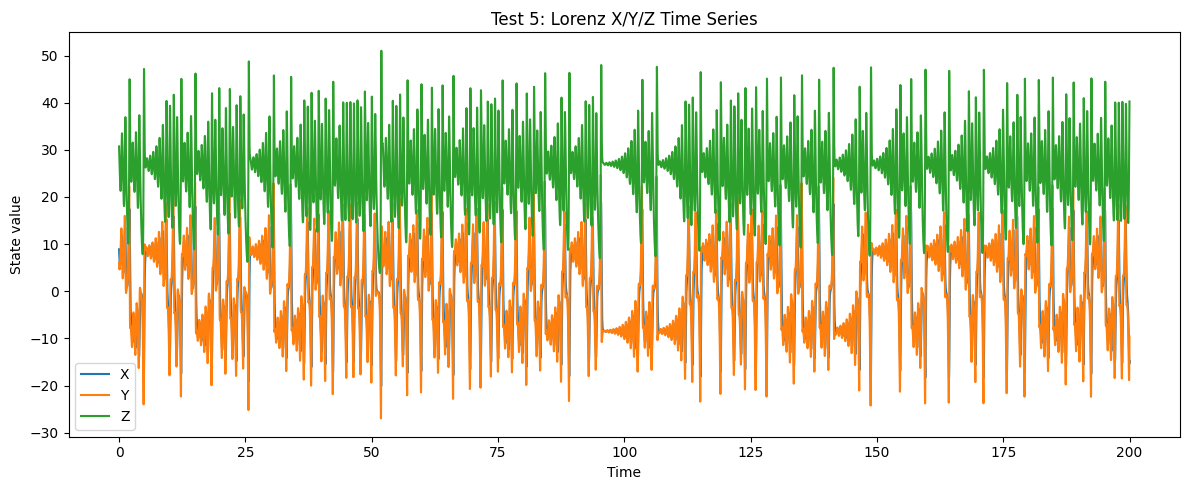


TEST 5 — LORENZ TIME SERIES
{
  "X": {
    "mean": 0.04912803054781029,
    "standard_deviation": 8.243081805130041,
    "minimum": -20.148772050182334,
    "maximum": 18.849408927704552
  },
  "Y": {
    "mean": 0.037555151030088406,
    "standard_deviation": 9.168665563874955,
    "minimum": -26.964398689183767,
    "maximum": 24.671129166536446
  },
  "Z": {
    "mean": 25.14024877943142,
    "standard_deviation": 7.591698971299893,
    "minimum": 3.850737030073053,
    "maximum": 51.02503676951182
  }
}


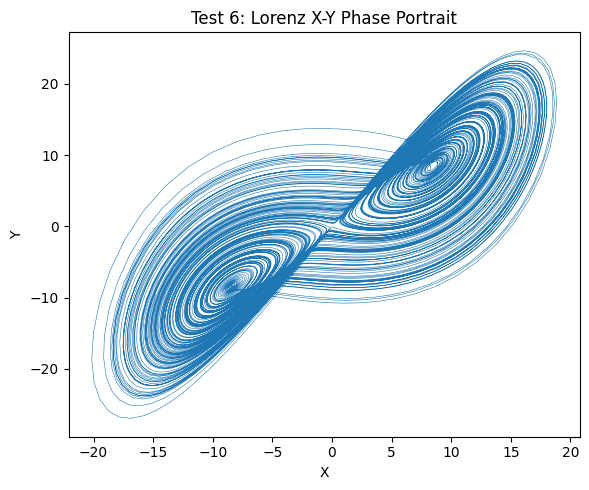

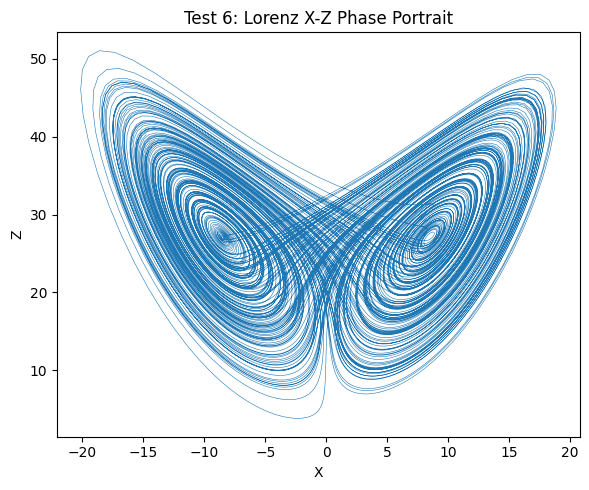

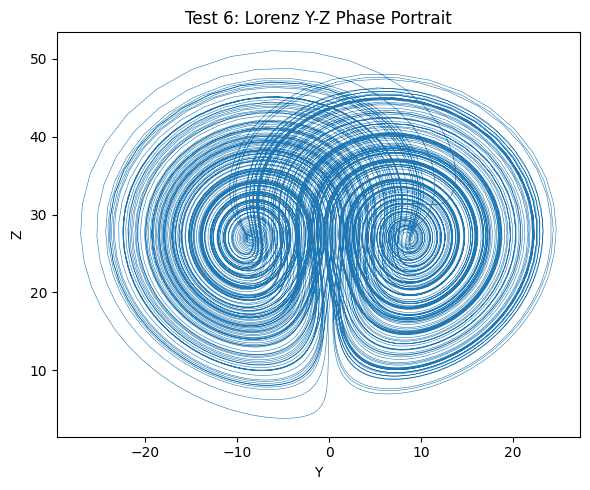


TEST 6 — PHASE PORTRAITS
Saved X-Y, X-Z and Y-Z phase portraits.

TEST 7 — LARGEST LYAPUNOV EXPONENT
{
  "estimated_LLE_per_time_unit": 1.025546726282469,
  "time_step": 0.01,
  "warmup_steps": 1000,
  "estimation_steps": 20000,
  "initial_perturbation": 1e-08,
  "note": "Numerical estimate for this discretized Lorenz implementation; it must be compared using the same estimator and parameters as the cited reference paper."
}


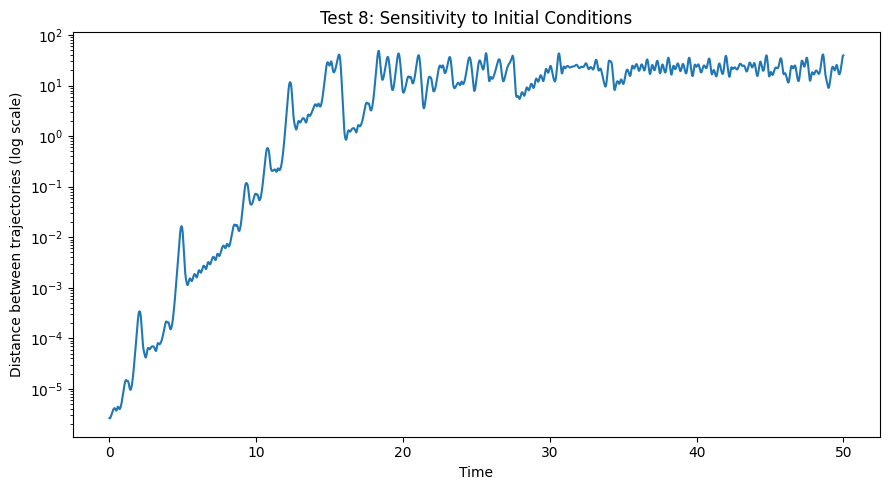


TEST 8 — INITIAL-CONDITION SENSITIVITY
{
  "initial_perturbation": 1e-09,
  "final_distance": 39.73720792795238,
  "maximum_distance": 49.006618533758896,
  "steps": 5000,
  "time_step": 0.01,
  "plot": "test8_initial_condition_sensitivity.png"
}

ALL EIGHT TESTS COMPLETED
Report JSON: /content/fydp_final_video_audio/eight_test_results/eight_test_report.json
Report TXT: /content/fydp_final_video_audio/eight_test_results/eight_test_report.txt
Plots and reports saved in: /content/fydp_final_video_audio/eight_test_results


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ================================================================
# FYDP: EIGHT STATISTICAL TESTS FOR COMBINED VIDEO + AUDIO
# Run AFTER the final encryption/decryption cell completes.
#
# Tests 1-4: Shannon entropy, correlation, NPCR, UACI
# Tests 5-8: Lorenz time series, phase portraits, LLE,
#            initial-condition sensitivity
# ================================================================

import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

TEST_DIR = os.path.join(WORK, "eight_test_results")
os.makedirs(TEST_DIR, exist_ok=True)

results = {}

# ------------------------------------------------
# Helper functions
# ------------------------------------------------

def shannon_entropy(values):
    values = np.asarray(values).ravel()
    counts = np.bincount(values.astype(np.int64))
    probabilities = counts[counts > 0] / values.size
    return float(-np.sum(probabilities * np.log2(probabilities)))


def safe_corr(a, b):
    a = np.asarray(a, dtype=np.float64).ravel()
    b = np.asarray(b, dtype=np.float64).ravel()

    if a.size < 2 or np.std(a) == 0 or np.std(b) == 0:
        return float("nan")

    return float(np.corrcoef(a, b)[0, 1])


def image_correlations(image):
    """Horizontal, vertical and diagonal adjacent-pixel correlations."""
    image = np.asarray(image)
    output = {}

    for channel, name in enumerate(("R", "G", "B")):
        plane = image[:, :, channel]

        output[name] = {
            "horizontal": safe_corr(plane[:, :-1], plane[:, 1:]),
            "vertical": safe_corr(plane[:-1, :], plane[1:, :]),
            "diagonal": safe_corr(plane[:-1, :-1], plane[1:, 1:])
        }

    return output


def audio_channel_correlations(audio):
    audio = np.asarray(audio)
    channels = audio[:, None] if audio.ndim == 1 else audio
    channel_results = []

    for channel in range(channels.shape[1]):
        samples = channels[:, channel]
        channel_results.append(
            safe_corr(samples[:-1], samples[1:])
        )

    return {
        "per_channel": channel_results,
        "mean": float(np.nanmean(channel_results))
        if np.any(np.isfinite(channel_results)) else float("nan")
    }


def save_plot(filename):
    path = os.path.join(TEST_DIR, filename)
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()
    return path


# ------------------------------------------------
# Prepare actual encrypted data
# ------------------------------------------------

frame_files = sorted(
    f for f in os.listdir(ENCRYPTED_DIR)
    if f.lower().endswith(".png")
)

if not frame_files:
    raise RuntimeError("No encrypted PNG frames found.")

encrypted_first_bgr = cv2.imread(
    os.path.join(ENCRYPTED_DIR, frame_files[0])
)
if encrypted_first_bgr is None:
    raise RuntimeError("Could not read the first encrypted frame.")

encrypted_first = cv2.cvtColor(
    encrypted_first_bgr, cv2.COLOR_BGR2RGB
)

original_first = display_frames["First"][0]

# ================================================================
# TEST 1 — SHANNON ENTROPY
# Calculate video entropy across all encrypted frames, per RGB
# channel. Calculate audio entropy using 16-bit PCM bit patterns.
# ================================================================

video_counts = np.zeros((3, 256), dtype=np.int64)
video_pixels = 0

for filename in frame_files:
    image_bgr = cv2.imread(os.path.join(ENCRYPTED_DIR, filename))
    if image_bgr is None:
        raise RuntimeError(f"Could not read {filename}")

    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    for c in range(3):
        video_counts[c] += np.bincount(
            image[:, :, c].ravel(), minlength=256
        )

    video_pixels += image.shape[0] * image.shape[1]


video_entropy = {}

for c, name in enumerate(("R", "G", "B")):
    p = video_counts[c] / video_counts[c].sum()
    p = p[p > 0]
    video_entropy[name] = float(-np.sum(p * np.log2(p)))

audio_unsigned = encrypted_audio.view(np.uint16).ravel()
audio_entropy = shannon_entropy(audio_unsigned)

results["1_shannon_entropy"] = {
    "encrypted_video_per_channel_bits": video_entropy,
    "encrypted_audio_16bit_symbols_bits": audio_entropy,
    "video_frames_tested": len(frame_files),
    "interpretation": (
        "For 8-bit video channels, the theoretical maximum is 8 bits. "
        "For 16-bit audio symbols, it is 16 bits. High entropy alone "
        "does not establish encryption security."
    )
}

print("\nTEST 1 — SHANNON ENTROPY")
print(json.dumps(results["1_shannon_entropy"], indent=2))


# ================================================================
# TEST 2 — CORRELATION COEFFICIENT
# Video: horizontal, vertical and diagonal pixel correlations.
# Audio: correlation between adjacent samples, per channel.
# ================================================================

video_corr = image_correlations(encrypted_first)
audio_corr = audio_channel_correlations(encrypted_audio)

results["2_correlation"] = {
    "encrypted_first_video_frame": video_corr,
    "encrypted_audio": audio_corr
}

print("\nTEST 2 — CORRELATION")
print(json.dumps(results["2_correlation"], indent=2))


# ================================================================
# Recreate the FIRST video frame's key using the existing method.
# This supports a proper differential test: plaintext and modified
# plaintext are encrypted with exactly the same key.
# ================================================================

x, y, z = X0, Y0, Z0

for _ in range(WARMUP_STEPS):
    x, y, z = lorenz_step(x, y, z)

first_frame_key, _, _, _ = generate_video_frame_key(
    HEIGHT, WIDTH, x, y, z
)

if first_frame_key.shape != original_first.shape:
    raise RuntimeError(
        "First-frame key and original frame have different shapes."
    )


# ================================================================
# TEST 3 — NPCR
# Modify one plaintext pixel/channel and encrypt both versions
# using the same key stream. Report video pixel NPCR and audio
# sample NPCR.
# ================================================================

modified_frame = original_first.copy()
modified_frame[0, 0, 0] = (
    int(modified_frame[0, 0, 0]) + 1
) % 256

cipher_frame_a = np.bitwise_xor(original_first, first_frame_key)
cipher_frame_b = np.bitwise_xor(modified_frame, first_frame_key)

video_changed_pixels = np.any(
    cipher_frame_a != cipher_frame_b, axis=2
)

video_npcr = float(100 * np.count_nonzero(
    video_changed_pixels
) / video_changed_pixels.size)

audio_plain_bits = original_audio.reshape(-1).view(np.uint16).copy()
audio_modified_bits = audio_plain_bits.copy()

audio_modified_bits[len(audio_modified_bits) // 2] ^= np.uint16(1)

audio_cipher_a = np.bitwise_xor(audio_plain_bits, audio_keys)
audio_cipher_b = np.bitwise_xor(audio_modified_bits, audio_keys)

audio_npcr = float(100 * np.count_nonzero(
    audio_cipher_a != audio_cipher_b
) / audio_cipher_a.size)

results["3_npcr"] = {
    "video_first_frame_percent": video_npcr,
    "audio_percent": audio_npcr,
    "method": (
        "One plaintext value is changed while the original key stream "
        "is held fixed. Video NPCR counts changed pixels; audio NPCR "
        "counts changed PCM samples."
    )
}

print("\nTEST 3 — NPCR")
print(json.dumps(results["3_npcr"], indent=2))


# ================================================================
# TEST 4 — UACI
# Average normalized intensity difference between the two
# ciphertexts from Test 3.
# ================================================================

video_uaci = float(
    100 * np.mean(
        np.abs(
            cipher_frame_a.astype(np.int16)
            - cipher_frame_b.astype(np.int16)
        )
    ) / 255.0
)

audio_uaci = float(
    100 * np.mean(
        np.abs(
            audio_cipher_a.astype(np.int32)
            - audio_cipher_b.astype(np.int32)
        )
    ) / 65535.0
)

results["4_uaci"] = {
    "video_first_frame_percent": video_uaci,
    "audio_percent": audio_uaci,
    "method": (
        "Normalized average absolute difference between ciphertexts "
        "for the one-unit plaintext modification used in Test 3."
    )
}

print("\nTEST 4 — UACI")
print(json.dumps(results["4_uaci"], indent=2))


# ================================================================
# Prepare Lorenz trajectory using the same Euler equations,
# initial conditions, parameters and warm-up.
# ================================================================

TRACE_STEPS = 20000

x, y, z = X0, Y0, Z0

for _ in range(WARMUP_STEPS):
    x, y, z = lorenz_step(x, y, z)

trajectory = np.empty((TRACE_STEPS, 3), dtype=np.float64)

for i in range(TRACE_STEPS):
    trajectory[i] = (x, y, z)
    x, y, z = lorenz_step(x, y, z)

# ================================================================
# TEST 5 — X/Y/Z TIME-SERIES ANALYSIS
# ================================================================

time_axis = np.arange(TRACE_STEPS) * DT
time_stats = {}

for i, name in enumerate(("X", "Y", "Z")):
    series = trajectory[:, i]

    time_stats[name] = {
        "mean": float(np.mean(series)),
        "standard_deviation": float(np.std(series)),
        "minimum": float(np.min(series)),
        "maximum": float(np.max(series))
    }

plt.figure(figsize=(12, 5))
plt.plot(time_axis, trajectory[:, 0], label="X")
plt.plot(time_axis, trajectory[:, 1], label="Y")
plt.plot(time_axis, trajectory[:, 2], label="Z")
plt.xlabel("Time")
plt.ylabel("State value")
plt.title("Test 5: Lorenz X/Y/Z Time Series")
plt.legend()
save_plot("test5_lorenz_time_series.png")

results["5_lorenz_time_series"] = time_stats

print("\nTEST 5 — LORENZ TIME SERIES")
print(json.dumps(time_stats, indent=2))


# ================================================================
# TEST 6 — PHASE PORTRAITS
# ================================================================

plt.figure(figsize=(6, 5))
plt.plot(trajectory[:, 0], trajectory[:, 1], linewidth=0.4)
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Test 6: Lorenz X-Y Phase Portrait")
save_plot("test6_phase_xy.png")

plt.figure(figsize=(6, 5))
plt.plot(trajectory[:, 0], trajectory[:, 2], linewidth=0.4)
plt.xlabel("X")
plt.ylabel("Z")
plt.title("Test 6: Lorenz X-Z Phase Portrait")
save_plot("test6_phase_xz.png")

plt.figure(figsize=(6, 5))
plt.plot(trajectory[:, 1], trajectory[:, 2], linewidth=0.4)
plt.xlabel("Y")
plt.ylabel("Z")
plt.title("Test 6: Lorenz Y-Z Phase Portrait")
save_plot("test6_phase_yz.png")

results["6_phase_portraits"] = {
    "plots": [
        "test6_phase_xy.png",
        "test6_phase_xz.png",
        "test6_phase_yz.png"
    ],
    "interpretation": (
        "Visualizes the Lorenz state-space trajectory. The plot alone "
        "does not prove cryptographic security."
    )
}

print("\nTEST 6 — PHASE PORTRAITS")
print("Saved X-Y, X-Z and Y-Z phase portraits.")


# ================================================================
# TEST 7 — LARGEST LYAPUNOV EXPONENT (LLE)
#
# Two nearby trajectories are repeatedly compared and the separation
# is renormalized. This is a numerical estimate; compare against the
# precise estimator and settings required by your cited paper.
# ================================================================

def estimate_lle(steps=20000, epsilon=1e-8):
    base = np.array([X0, Y0, Z0], dtype=np.float64)

    for _ in range(WARMUP_STEPS):
        base[:] = lorenz_step(*base)

    perturbed = base.copy()
    perturbed[0] += epsilon

    log_sum = 0.0
    valid_steps = 0

    for _ in range(steps):
        base[:] = lorenz_step(*base)
        perturbed[:] = lorenz_step(*perturbed)

        delta = perturbed - base
        distance = float(np.linalg.norm(delta))

        if not np.isfinite(distance) or distance <= 0:
            continue

        log_sum += np.log(distance / epsilon)
        valid_steps += 1

        perturbed = base + (epsilon / distance) * delta

    if valid_steps == 0:
        return float("nan")

    return float(log_sum / (valid_steps * DT))


lle = estimate_lle()

results["7_largest_lyapunov_exponent"] = {
    "estimated_LLE_per_time_unit": lle,
    "time_step": DT,
    "warmup_steps": WARMUP_STEPS,
    "estimation_steps": 20000,
    "initial_perturbation": 1e-8,
    "note": (
        "Numerical estimate for this discretized Lorenz implementation; "
        "it must be compared using the same estimator and parameters as "
        "the cited reference paper."
    )
}

print("\nTEST 7 — LARGEST LYAPUNOV EXPONENT")
print(json.dumps(results["7_largest_lyapunov_exponent"], indent=2))


# ================================================================
# TEST 8 — INITIAL-CONDITION SENSITIVITY
# Compare trajectories starting from X0 and X0 + epsilon.
# ================================================================

SENSITIVITY_STEPS = 5000
EPSILON = 1e-9

base = np.array([X0, Y0, Z0], dtype=np.float64)
perturbed = np.array([X0 + EPSILON, Y0, Z0], dtype=np.float64)

for _ in range(WARMUP_STEPS):
    base[:] = lorenz_step(*base)
    perturbed[:] = lorenz_step(*perturbed)

distances = np.empty(SENSITIVITY_STEPS, dtype=np.float64)

for i in range(SENSITIVITY_STEPS):
    base[:] = lorenz_step(*base)
    perturbed[:] = lorenz_step(*perturbed)
    distances[i] = np.linalg.norm(perturbed - base)

plt.figure(figsize=(9, 5))
plt.semilogy(
    np.arange(SENSITIVITY_STEPS) * DT,
    np.maximum(distances, np.finfo(float).tiny)
)
plt.xlabel("Time")
plt.ylabel("Distance between trajectories (log scale)")
plt.title("Test 8: Sensitivity to Initial Conditions")
save_plot("test8_initial_condition_sensitivity.png")

results["8_initial_condition_sensitivity"] = {
    "initial_perturbation": EPSILON,
    "final_distance": float(distances[-1]),
    "maximum_distance": float(np.max(distances)),
    "steps": SENSITIVITY_STEPS,
    "time_step": DT,
    "plot": "test8_initial_condition_sensitivity.png"
}

print("\nTEST 8 — INITIAL-CONDITION SENSITIVITY")
print(json.dumps(results["8_initial_condition_sensitivity"], indent=2))


# ================================================================
# SAVE RESULTS
# ================================================================

report_file = os.path.join(TEST_DIR, "eight_test_report.json")

with open(report_file, "w") as f:
    json.dump(results, f, indent=2, allow_nan=True)

text_report = os.path.join(TEST_DIR, "eight_test_report.txt")

with open(text_report, "w") as f:
    f.write("FYDP COMBINED VIDEO + AUDIO: EIGHT-TEST REPORT\n")
    f.write("=" * 60 + "\n\n")

    for test_name, test_results in results.items():
        f.write(test_name.upper().replace("_", " ") + "\n")
        f.write("-" * 50 + "\n")
        f.write(json.dumps(test_results, indent=2, allow_nan=True))
        f.write("\n\n")

    f.write("IMPORTANT INTERPRETATION\n")
    f.write(
        "NPCR/UACI here use a one-unit plaintext change and a fixed "
        "key stream. For a plaintext-independent XOR key stream, a "
        "small plaintext change is expected to remain localized. "
        "This is a limitation of diffusion, not a failed decryption.\n"
    )

print("\n" + "=" * 65)
print("ALL EIGHT TESTS COMPLETED")
print("=" * 65)
print("Report JSON:", report_file)
print("Report TXT:", text_report)
print("Plots and reports saved in:", TEST_DIR)

# Download the report and the plots as one ZIP archive.
import shutil
zip_path = shutil.make_archive(
    "/content/fydp_eight_test_results",
    "zip",
    TEST_DIR
)

files.download(zip_path)
